# Diabetes Risk Screening Tool
**NextGen Institute · Machine Learning · Final Project (Idea 11)**

**Data:** CDC Diabetes Health Indicators (BRFSS 2015 survey) — [UCI repository](https://archive.ics.uci.edu/dataset/891)

> ⚠️ This is a *screening aid*, not a medical diagnosis.

## 1 · Problem framing
- **Who has the problem?** Public-health programs and clinics. Many people have diabetes or prediabetes and do not know it.
- **Decision the model supports:** after a short questionnaire, *should this person be advised to see a doctor for a blood test?*
- **Target:** `Diabetes_binary` (0 = no diabetes, 1 = prediabetes or diabetes).
- **Metric that matters: Recall (sensitivity)**, supported by ROC-AUC and PR-AUC. Missing a sick person (false negative) delays diagnosis. A false alarm only costs one extra blood test. Accuracy is misleading because the classes are imbalanced.
- **Design constraint:** a *short* questionnaire (stretch goal: 5–7 questions).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, json
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve, brier_score_loss)
sns.set_theme(style="whitegrid", palette="deep"); RS=42
import os; os.makedirs("figures",exist_ok=True); os.makedirs("models",exist_ok=True)
def savefig(n): plt.tight_layout(); plt.savefig(f"figures/{n}.png",dpi=150,bbox_inches="tight")

ModuleNotFoundError: No module named 'numpy'

## 2 · Data understanding
Source: CDC **BRFSS 2015** health survey (cleaned version published on UCI). Every row is one survey respondent.

In [ ]:
raw = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print("Duplicate rows:", int(raw.duplicated().sum()))
print("All dtypes:", raw.dtypes.unique())
display(raw.Diabetes_binary.value_counts(normalize=True).rename("share").to_frame().round(4))
display(raw.describe().T.round(2))

Shape: (253680, 22)
Missing values: 0
Duplicate rows: 24206
All dtypes: [dtype('float64')]


,share
Diabetes_binary,
0.0,0.8607
1.0,0.1393


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.14,0.35,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.43,0.49,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.96,0.19,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.44,0.50,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.04,0.20,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.09,0.29,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.76,0.43,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.63,0.48,0.0,0.0,1.0,1.0,1.0


### Column dictionary
| Column | Meaning | Type |
|---|---|---|
| Diabetes_binary | **Target**: 1 = prediabetes/diabetes | binary |
| HighBP, HighChol | Told by a doctor: high blood pressure / cholesterol | binary |
| CholCheck | Cholesterol check in last 5 years | binary |
| BMI | Body Mass Index | numeric |
| Smoker | Smoked ≥100 cigarettes in life | binary |
| Stroke, HeartDiseaseorAttack | Ever had a stroke / heart disease or attack | binary |
| PhysActivity | Physical activity in last 30 days (excluding job) | binary |
| Fruits, Veggies | Eats fruit / vegetables daily | binary |
| HvyAlcoholConsump | Heavy drinker | binary |
| AnyHealthcare, NoDocbcCost | Has health coverage / skipped doctor because of cost | binary |
| GenHlth | General health, 1 (excellent) – 5 (poor) | ordinal |
| MentHlth, PhysHlth | Bad mental / physical health days in last 30 | numeric (0–30) |
| DiffWalk | Difficulty walking or climbing stairs | binary |
| Sex | 0 = female, 1 = male | binary |
| Age | 13 age groups: 1 = 18–24 … 13 = 80+ | ordinal |
| Education | 1–6 | ordinal |
| Income | 1–8 | ordinal |

**Data-quality decisions:** no missing values. Duplicated rows are removed *before* splitting, so an identical respondent can never sit in both train and test (leakage).

In [ ]:
df = raw.drop_duplicates().reset_index(drop=True)
y = df.pop("Diabetes_binary").astype(int); X = df.astype(float)
print(f"After removing duplicates: {len(X):,} rows (removed {len(raw)-len(X):,})")
print(f"Positive rate: {y.mean():.3%}  -> imbalance ratio {(1-y.mean())/y.mean():.1f} : 1")

After removing duplicates: 229,474 rows (removed 24,206)
Positive rate: 15.295%  -> imbalance ratio 5.5 : 1


## 3 · Exploratory Data Analysis

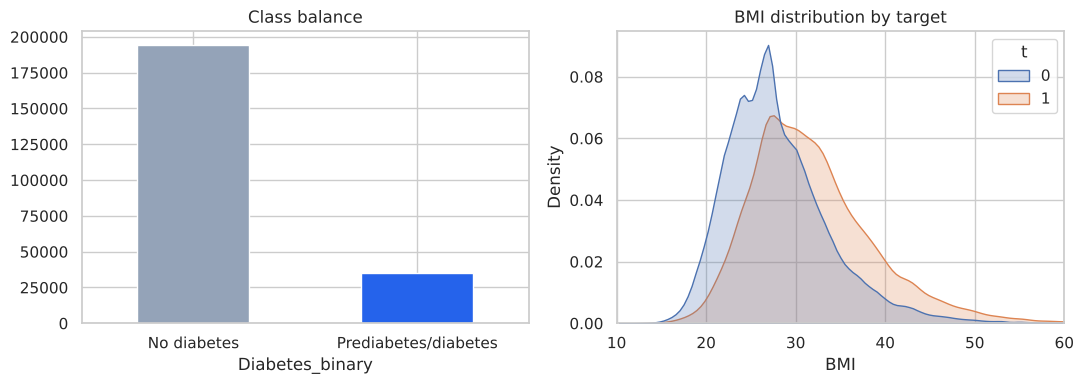

,BMI,Age,GenHlth,PhysHlth,MentHlth,Income,Education
Diabetes_binary,,,,,,,
No diabetes,28.10,7.85,2.48,4.08,3.33,6.01,5.02
Diabetes,31.96,9.38,3.30,8.01,4.49,5.20,4.74


In [ ]:
fig,ax=plt.subplots(1,2,figsize=(11,4))
y.map({0:"No diabetes",1:"Prediabetes/diabetes"}).value_counts().plot.bar(ax=ax[0],color=["#94a3b8","#2563eb"]); ax[0].set_title("Class balance"); ax[0].tick_params(axis="x",rotation=0)
sns.kdeplot(data=X.assign(t=y),x="BMI",hue="t",common_norm=False,fill=True,ax=ax[1]); ax[1].set_title("BMI distribution by target"); ax[1].set_xlim(10,60)
savefig("eda_balance_bmi"); plt.show()
display(X.groupby(y)[["BMI","Age","GenHlth","PhysHlth","MentHlth","Income","Education"]].mean().round(2).rename(index={0:"No diabetes",1:"Diabetes"}))

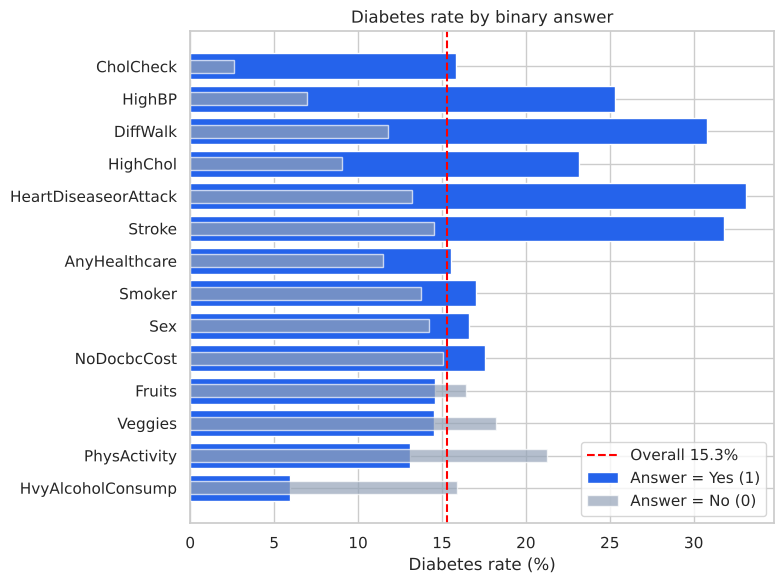

In [ ]:
binary=[c for c in X.columns if X[c].nunique()==2]
rate=pd.DataFrame({c:{"Yes":y[X[c]==1].mean(),"No":y[X[c]==0].mean()} for c in binary}).T
rate["lift"]=rate.Yes/rate.No
rate=rate.sort_values("lift")
fig,ax=plt.subplots(figsize=(8,6))
ax.barh(rate.index,rate.Yes*100,color="#2563eb",label="Answer = Yes (1)"); ax.barh(rate.index,rate.No*100,color="#94a3b8",alpha=.7,height=.4,label="Answer = No (0)")
ax.axvline(y.mean()*100,color="red",ls="--",label=f"Overall {y.mean():.1%}"); ax.set_xlabel("Diabetes rate (%)"); ax.set_title("Diabetes rate by binary answer"); ax.legend()
savefig("eda_binary_rates"); plt.show()

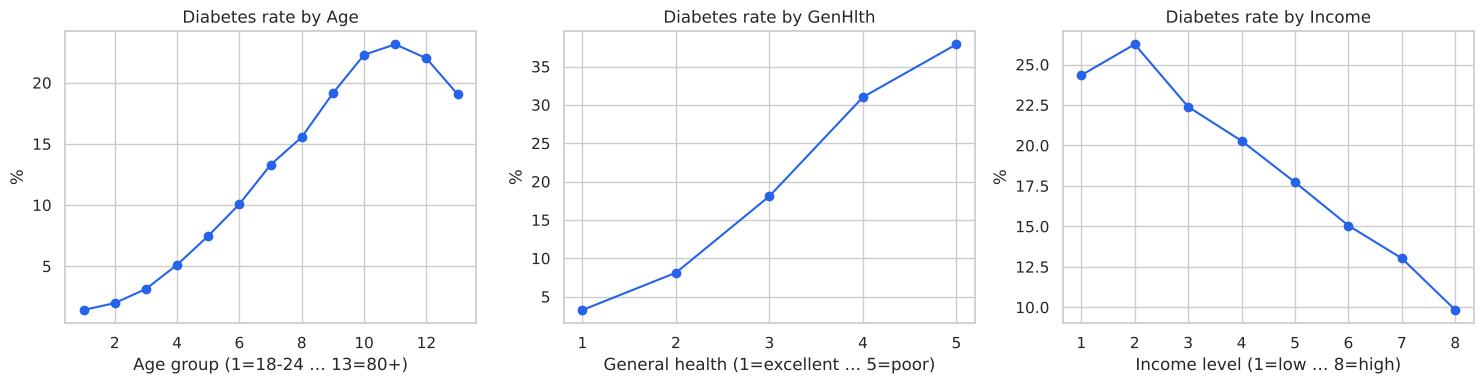

,diabetes rate % by BMI band
BMI,
<18.5,5.5
18.5-25,7.3
25-30,14.0
30-35,21.9
35+,30.8


In [ ]:
fig,ax=plt.subplots(1,3,figsize=(15,4))
for a,c,t in zip(ax,["Age","GenHlth","Income"],["Age group (1=18-24 … 13=80+)","General health (1=excellent … 5=poor)","Income level (1=low … 8=high)"]):
    (X.groupby(c).apply(lambda g:y[g.index].mean())*100).plot(marker="o",ax=a,color="#2563eb"); a.set_title(f"Diabetes rate by {c}"); a.set_xlabel(t); a.set_ylabel("%")
savefig("eda_ordinal_rates"); plt.show()
bmi_band=pd.cut(X.BMI,[0,18.5,25,30,35,100],labels=["<18.5","18.5-25","25-30","30-35","35+"])
display((y.groupby(bmi_band).mean()*100).round(1).rename("diabetes rate % by BMI band").to_frame())

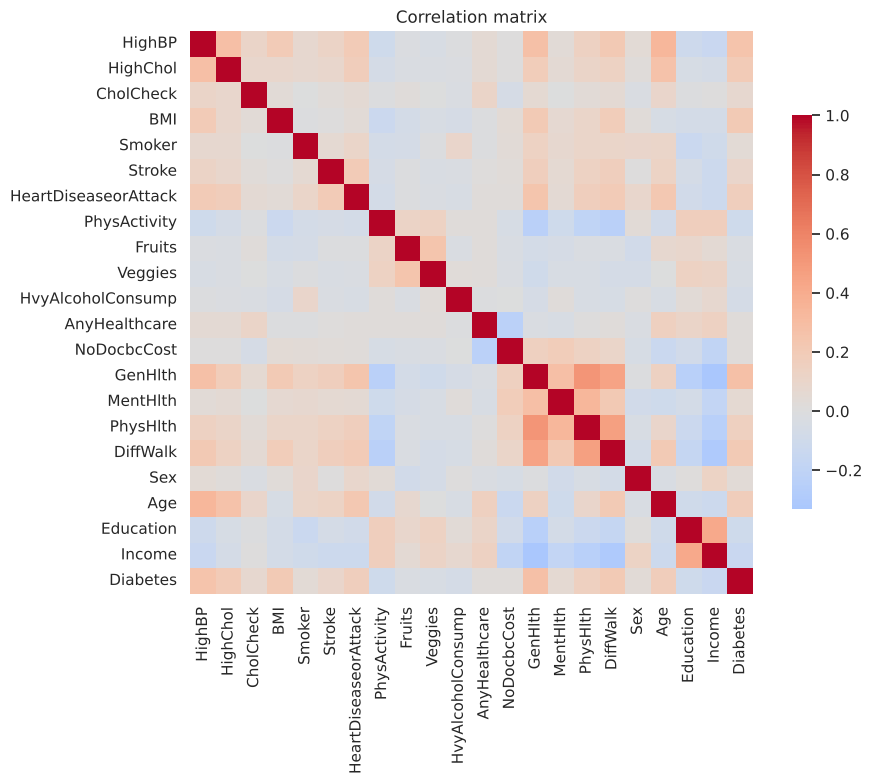

,corr with target
GenHlth,0.277
HighBP,0.254
DiffWalk,0.205
BMI,0.205
HighChol,0.195
Age,0.177
HeartDiseaseorAttack,0.168
PhysHlth,0.156


In [ ]:
plt.figure(figsize=(10,8)); corr=X.assign(Diabetes=y).corr()
sns.heatmap(corr,cmap="coolwarm",center=0,annot=False,square=True,cbar_kws={"shrink":.7}); plt.title("Correlation matrix"); savefig("eda_corr"); plt.show()
display(corr["Diabetes"].drop("Diabetes").sort_values(ascending=False).round(3).to_frame("corr with target").head(8))

In [ ]:
g=lambda c:y[X[c]==1].mean()/y[X[c]==0].mean()
a=y.groupby(X.Age).mean()
display(Markdown(f'''### Written insights
1. **Imbalance:** only {y.mean():.1%} are positive, so accuracy is useless (always answering "no" scores {1-y.mean():.1%}). Recall, PR-AUC and threshold tuning are needed.
2. **Strongest signals:** self-rated health (diabetes rate rises from {y[X.GenHlth==1].mean():.1%} to {y[X.GenHlth==5].mean():.1%} between "excellent" and "poor"), high blood pressure (×{g("HighBP"):.1f} risk), difficulty walking (×{g("DiffWalk"):.1f}) and high cholesterol (×{g("HighChol"):.1f}).
3. **Age and weight:** the rate climbs from {a.iloc[0]:.1%} in the youngest group to {a.max():.1%} at the peak age group; people with BMI 35+ have a rate of {y[bmi_band=="35+"].mean():.1%} vs {y[bmi_band=="18.5-25"].mean():.1%} for normal weight.
4. **Social factors:** the diabetes rate falls from {y[X.Income==1].mean():.1%} (lowest income) to {y[X.Income==8].mean():.1%} (highest) → screening campaigns should target lower-income groups.
5. **Hypothesis:** a small set of simple questions (health, blood pressure, BMI, age, cholesterol, walking) should capture most of the predictive power.'''))

### Written insights
1. **Imbalance:** only 15.3% are positive, so accuracy is useless (always answering "no" scores 84.7%). Recall, PR-AUC and threshold tuning are needed.
2. **Strongest signals:** self-rated health (diabetes rate rises from 3.3% to 37.9% between "excellent" and "poor"), high blood pressure (×3.6 risk), difficulty walking (×2.6) and high cholesterol (×2.6).
3. **Age and weight:** the rate climbs from 1.4% in the youngest group to 23.1% at the peak age group; people with BMI 35+ have a rate of 30.8% vs 7.3% for normal weight.
4. **Social factors:** the diabetes rate falls from 24.3% (lowest income) to 9.8% (highest) → screening campaigns should target lower-income groups.
5. **Hypothesis:** a small set of simple questions (health, blood pressure, BMI, age, cholesterol, walking) should capture most of the predictive power.

## 4 · Preprocessing & pipeline
- The data is **split first** (80/20, stratified); nothing is fitted before the split.
- All fitted steps (scaling) live **inside a scikit-learn `Pipeline`**, so cross-validation never leaks.
- No missing values or encoding needed (all numeric/ordinal/binary). Outliers: BMI up to ~98 are real survey values; tree models are robust, logistic regression uses a scaler.
- Class imbalance is handled with `class_weight` for the first comparison.

In [ ]:
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.2,stratify=y,random_state=RS)
print(f"Train {Xtr.shape}  positives {ytr.mean():.3%} | Test {Xte.shape}  positives {yte.mean():.3%}")
num=["BMI","MentHlth","PhysHlth","GenHlth","Age","Education","Income"]
def prep(cols): return ColumnTransformer([("scale",StandardScaler(),[c for c in num if c in cols])],remainder="passthrough")
cv=StratifiedKFold(5,shuffle=True,random_state=RS)

Train (183579, 21)  positives 15.295% | Test (45895, 21)  positives 15.294%


## 5 · Modeling — baseline + three algorithms (5-fold CV on training data)

In [ ]:
models={
 "Baseline (majority)":Pipeline([("m",DummyClassifier(strategy="most_frequent"))]),
 "Logistic Regression":Pipeline([("prep",prep(X.columns)),("m",LogisticRegression(max_iter=1000,class_weight="balanced"))]),
 "Random Forest":Pipeline([("prep",prep(X.columns)),("m",RandomForestClassifier(n_estimators=200,min_samples_leaf=20,class_weight="balanced_subsample",n_jobs=-1,random_state=RS))]),
 "Gradient Boosting":Pipeline([("prep",prep(X.columns)),("m",HistGradientBoostingClassifier(random_state=RS))]),
}
rows=[]
for n,m in models.items():
    o=cross_validate(m,Xtr,ytr,cv=cv,scoring={"a":"roc_auc","r":"recall"},n_jobs=1)
    rows.append((n,o["test_a"].mean(),o["test_a"].std(),o["test_r"].mean()))
cvtab=pd.DataFrame(rows,columns=["Model","CV ROC-AUC","std","CV Recall @0.5"]).set_index("Model").round(4); display(cvtab)

,CV ROC-AUC,std,CV Recall @0.5
Model,,,
Baseline (majority),0.5000,0.0000,0.0000
Logistic Regression,0.8067,0.0010,0.7538
Random Forest,0.8127,0.0010,0.7338
Gradient Boosting,0.8147,0.0011,0.1551


## 6 · Hyperparameter tuning (random search, training data only)

In [ ]:
search=RandomizedSearchCV(models["Gradient Boosting"],{
  "m__learning_rate":[0.03,0.05,0.1],"m__max_leaf_nodes":[15,31,63],"m__max_iter":[150,300],
  "m__l2_regularization":[0,1,5],"m__min_samples_leaf":[20,50,100]},
  n_iter=10,scoring="roc_auc",cv=3,random_state=RS,n_jobs=1).fit(Xtr,ytr)
print("Best params:",search.best_params_); print(f"Best CV ROC-AUC: {search.best_score_:.4f}")
best=search.best_estimator_

Best params: {'m__min_samples_leaf': 100, 'm__max_leaf_nodes': 31, 'm__max_iter': 150, 'm__learning_rate': 0.05, 'm__l2_regularization': 5}
Best CV ROC-AUC: 0.8149


## 7 · Choosing the screening threshold (recall-first)
The default 0.5 threshold is wrong for screening. We pick the threshold using **out-of-fold predictions on the training set only** so that **recall ≥ 80 %**, and use a second, lower threshold (recall ≥ 95 %) to mark the *low-risk* group.
The final model is **not** class-weighted, so its probabilities are real risk estimates (checked with a calibration curve below).

In [ ]:
oof=cross_val_predict(best,Xtr,ytr,cv=cv,method="predict_proba")[:,1]
p,r,t=precision_recall_curve(ytr,oof)
thr_high=float(t[np.where(r[:-1]>=0.80)[0][-1]]); thr_low=float(t[np.where(r[:-1]>=0.95)[0][-1]])
print(f"High-risk threshold (recall>=80% in CV): {thr_high:.3f} | Low-risk cut-off (recall>=95%): {thr_low:.3f}")

High-risk threshold (recall>=80% in CV): 0.142 | Low-risk cut-off (recall>=95%): 0.054


## 8 · Final evaluation on the untouched test set

In [ ]:
best.fit(Xtr,ytr); proba=best.predict_proba(Xte)[:,1]
def row(name,pr,th):
    pdv=(pr>=th).astype(int)
    return dict(Model=name,Threshold=round(th,3),ROC_AUC=roc_auc_score(yte,pr),PR_AUC=average_precision_score(yte,pr),
                Recall=recall_score(yte,pdv),Precision=precision_score(yte,pdv,zero_division=0),F1=f1_score(yte,pdv,zero_division=0))
res=[]
for n,m in models.items():
    m.fit(Xtr,ytr)
    res.append(row(n,m.predict_proba(Xte)[:,1],0.5))
res.append(row("Gradient Boosting (tuned + threshold)",proba,thr_high))
res=pd.DataFrame(res).set_index("Model").round(4); display(res); res.to_csv("models/results.csv")

,Threshold,ROC_AUC,PR_AUC,Recall,Precision,F1
Model,,,,,,
Baseline (majority),0.500,0.5000,0.1529,0.0000,0.0000,0.0000
Logistic Regression,0.500,0.8106,0.4121,0.7601,0.3183,0.4487
Random Forest,0.500,0.8171,0.4420,0.7434,0.3334,0.4604
Gradient Boosting,0.500,0.8191,0.4466,0.1673,0.5965,0.2613
Gradient Boosting (tuned + threshold),0.142,0.8190,0.4459,0.8121,0.3098,0.4485


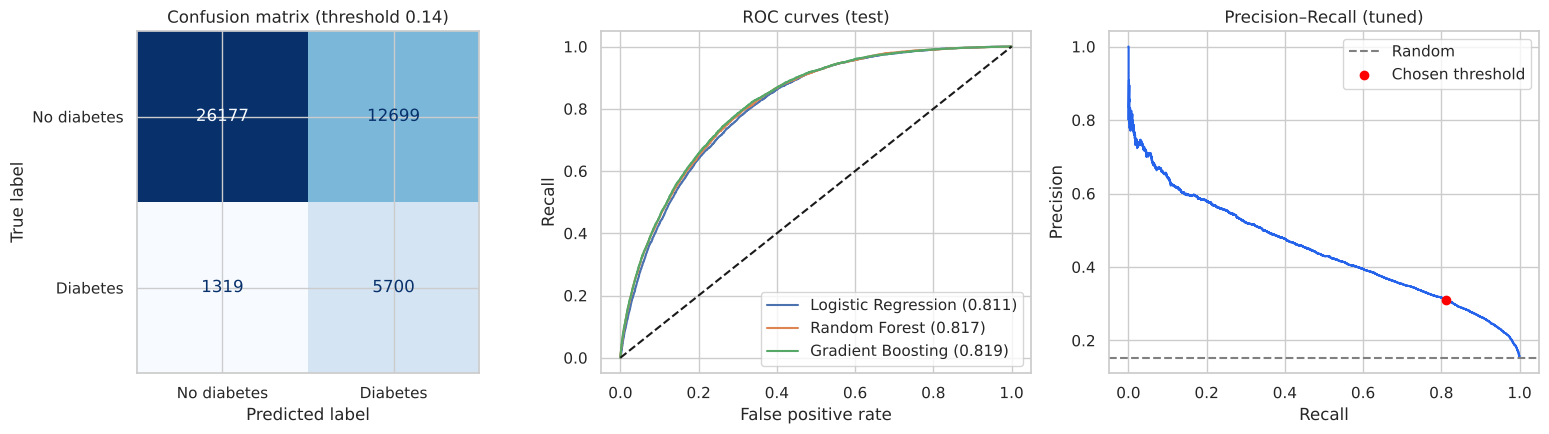

**Test set:** 5,700 diabetics caught, 1,319 missed (recall 81.2%); 12,699 false alarms → precision 31.0%; i.e. about **1 in 3.2** people flagged truly has the condition.

In [ ]:
pred=(proba>=thr_high).astype(int); cm=confusion_matrix(yte,pred)
fig,ax=plt.subplots(1,3,figsize=(16,4.5))
ConfusionMatrixDisplay(cm,display_labels=["No diabetes","Diabetes"]).plot(ax=ax[0],cmap="Blues",colorbar=False,values_format="d"); ax[0].set_title(f"Confusion matrix (threshold {thr_high:.2f})")
for n in ["Logistic Regression","Random Forest","Gradient Boosting"]:
    f,tp,_=roc_curve(yte,models[n].predict_proba(Xte)[:,1]); ax[1].plot(f,tp,label=f"{n} ({roc_auc_score(yte,models[n].predict_proba(Xte)[:,1]):.3f})")
ax[1].plot([0,1],[0,1],"k--"); ax[1].set_title("ROC curves (test)"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("Recall"); ax[1].legend()
pp,rr,_=precision_recall_curve(yte,proba); ax[2].plot(rr,pp,color="#2563eb"); ax[2].axhline(yte.mean(),color="gray",ls="--",label="Random"); ax[2].scatter([recall_score(yte,pred)],[precision_score(yte,pred)],color="red",zorder=5,label="Chosen threshold")
ax[2].set_xlabel("Recall"); ax[2].set_ylabel("Precision"); ax[2].set_title("Precision–Recall (tuned)"); ax[2].legend()
savefig("eval_curves"); plt.show()
tn,fp,fn,tp=cm.ravel()
display(Markdown(f"**Test set:** {tp:,} diabetics caught, {fn:,} missed (recall {tp/(tp+fn):.1%}); {fp:,} false alarms → precision {tp/(tp+fp):.1%}; i.e. about **1 in {(tp+fp)/tp:.1f}** people flagged truly has the condition."))

### Error analysis — who does the model miss?

,Missed (FN),Caught (TP)
Age,8.26,9.63
BMI,27.82,33.06
GenHlth,2.47,3.52
HighBP,0.36,0.84
HighChol,0.40,0.74
DiffWalk,0.12,0.44
PhysActivity,0.75,0.59


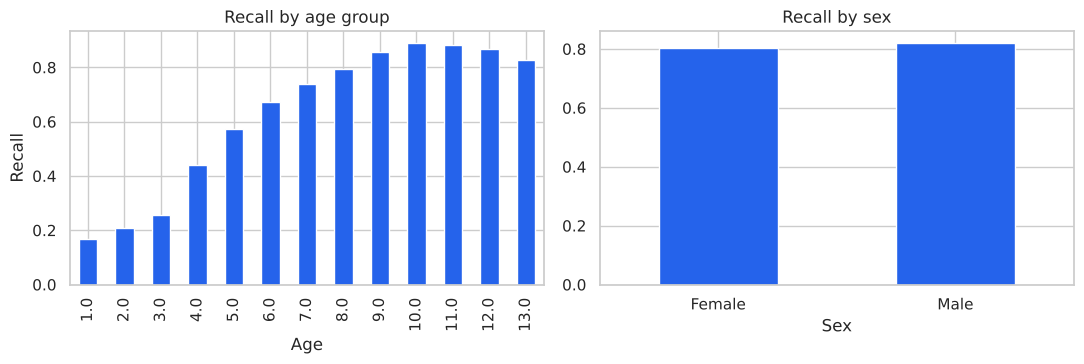

Missed patients are younger (8.3 vs 9.6 age group), lighter (BMI 27.8 vs 33.1) and report better general health (2.5 vs 3.5): the model struggles when a person *looks healthy on paper*.

In [ ]:
err=Xte.assign(y=yte.values,p=proba,pred=pred)
fn_=err[(err.y==1)&(err.pred==0)]; tp_=err[(err.y==1)&(err.pred==1)]
cmp=pd.DataFrame({"Missed (FN)":fn_[["Age","BMI","GenHlth","HighBP","HighChol","DiffWalk","PhysActivity"]].mean(),
                  "Caught (TP)":tp_[["Age","BMI","GenHlth","HighBP","HighChol","DiffWalk","PhysActivity"]].mean()}).round(2); display(cmp)
fig,ax=plt.subplots(1,2,figsize=(11,3.8))
(err.groupby("Age").apply(lambda g:recall_score(g.y,g.pred))).plot.bar(ax=ax[0],color="#2563eb"); ax[0].set_title("Recall by age group"); ax[0].set_ylabel("Recall")
(err.groupby("Sex").apply(lambda g:recall_score(g.y,g.pred))).rename({0:"Female",1:"Male"}).plot.bar(ax=ax[1],color="#2563eb"); ax[1].set_title("Recall by sex"); ax[1].tick_params(axis="x",rotation=0)
savefig("error_analysis"); plt.show()
display(Markdown(f"Missed patients are younger ({fn_.Age.mean():.1f} vs {tp_.Age.mean():.1f} age group), lighter (BMI {fn_.BMI.mean():.1f} vs {tp_.BMI.mean():.1f}) and report better general health ({fn_.GenHlth.mean():.1f} vs {tp_.GenHlth.mean():.1f}): the model struggles when a person *looks healthy on paper*."))

### Are the predicted probabilities trustworthy? (calibration & risk bands)

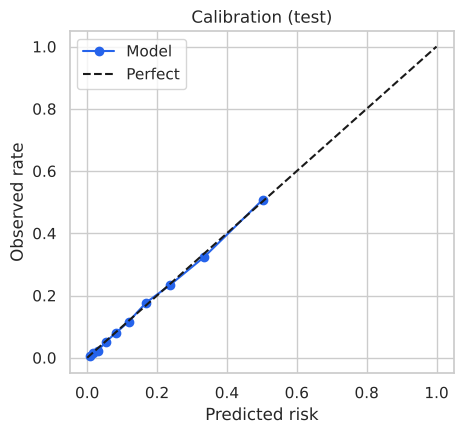

Brier score: 0.1048


,people,diabetes_rate,share_of_people,share_of_all_cases
band,,,,
Low,16347,0.019,0.356,0.045
Moderate,11149,0.090,0.243,0.143
High,18399,0.310,0.401,0.812


In [ ]:
fo,mp=calibration_curve(yte,proba,n_bins=10,strategy="quantile")
plt.figure(figsize=(4.8,4.5)); plt.plot(mp,fo,"o-",color="#2563eb",label="Model"); plt.plot([0,1],[0,1],"k--",label="Perfect"); plt.xlabel("Predicted risk"); plt.ylabel("Observed rate"); plt.title("Calibration (test)"); plt.legend(); savefig("calibration"); plt.show()
print("Brier score:",round(brier_score_loss(yte,proba),4))
bands=pd.cut(proba,[0,thr_low,thr_high,1.0001],labels=["Low","Moderate","High"],right=False)
bt=pd.DataFrame({"band":bands,"y":yte.values}).groupby("band").y.agg(people="count",diabetes_rate="mean"); bt["share_of_people"]=bt.people/bt.people.sum(); bt["share_of_all_cases"]=pd.DataFrame({"band":bands,"y":yte.values}).groupby("band").y.sum()/yte.sum()
display(bt.round(3))

## 9 · What drives the risk? (permutation importance)

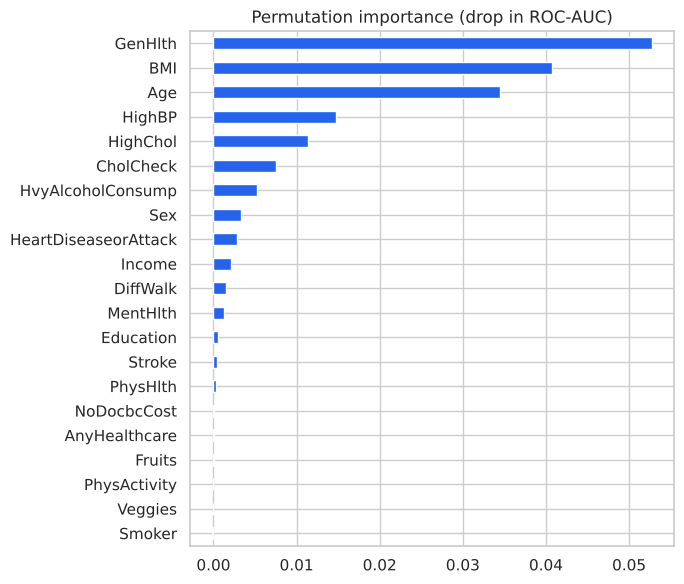

,importance
GenHlth,0.0528
BMI,0.0407
Age,0.0344
HighBP,0.0147
HighChol,0.0114
CholCheck,0.0075
HvyAlcoholConsump,0.0053
Sex,0.0033
HeartDiseaseorAttack,0.0029
Income,0.0021


In [ ]:
Xa,Xv,ya,yv=train_test_split(Xtr,ytr,test_size=0.2,stratify=ytr,random_state=RS)   # validation slice from TRAIN only
m_a=Pipeline(best.steps).fit(Xa,ya)
pi=permutation_importance(m_a,Xv.iloc[:15000],yv.iloc[:15000],scoring="roc_auc",n_repeats=3,random_state=RS,n_jobs=1)
imp=pd.Series(pi.importances_mean,index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(7,6)); imp.sort_values().plot.barh(color="#2563eb"); plt.title("Permutation importance (drop in ROC-AUC)"); savefig("importance"); plt.show()
display(imp.round(4).head(10).to_frame("importance"))

## 10 · Stretch goal — the smallest useful questionnaire
Question: how few questions keep most of the performance? Features are ranked by the importance above (computed on a validation slice of the *training* data) and the curve is also measured on that validation slice, never on the test set.

,val_ROC_AUC,val_PR_AUC,share_of_full_AUC_above_0.5
questions,,,
3,0.7897,0.3980,0.9117
5,0.8071,0.4300,0.9662
7,0.8111,0.4353,0.9790
10,0.8160,0.4438,0.9943
15,0.8177,0.4465,0.9996
21,0.8178,0.4480,1.0000


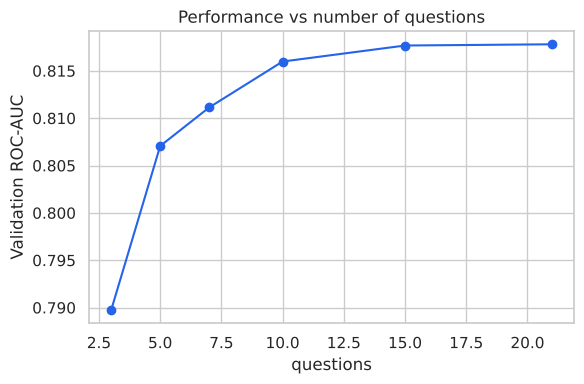

In [ ]:
order=list(imp.index); ks=[3,5,7,10,15,len(order)]; rows=[]
for k in ks:
    cols=order[:k]; mk=Pipeline([("prep",prep(cols)),("m",HistGradientBoostingClassifier(random_state=RS,**{k_[3:]:v for k_,v in search.best_params_.items()}))]).fit(Xa[cols],ya)
    pv=mk.predict_proba(Xv[cols])[:,1]; rows.append((k,roc_auc_score(yv,pv),average_precision_score(yv,pv)))
kt=pd.DataFrame(rows,columns=["questions","val_ROC_AUC","val_PR_AUC"]).set_index("questions"); kt["share_of_full_AUC_above_0.5"]=(kt.val_ROC_AUC-.5)/(kt.val_ROC_AUC.iloc[-1]-.5)
display(kt.round(4))
plt.figure(figsize=(6,4)); kt.val_ROC_AUC.plot(marker="o",color="#2563eb"); plt.ylabel("Validation ROC-AUC"); plt.title("Performance vs number of questions"); savefig("short_form_curve"); plt.show()

In [ ]:
K=7; short_cols=order[:K]; print("Short questionnaire:",short_cols)
short=Pipeline([("prep",prep(short_cols)),("m",HistGradientBoostingClassifier(random_state=RS,**{k_[3:]:v for k_,v in search.best_params_.items()}))])
oof_s=cross_val_predict(short,Xtr[short_cols],ytr,cv=cv,method="predict_proba")[:,1]; p_,r_,t_=precision_recall_curve(ytr,oof_s)
thr_s_high=float(t_[np.where(r_[:-1]>=0.80)[0][-1]]); thr_s_low=float(t_[np.where(r_[:-1]>=0.95)[0][-1]])
short.fit(Xtr[short_cols],ytr); ps=short.predict_proba(Xte[short_cols])[:,1]; pds=(ps>=thr_s_high).astype(int)
short_res=dict(questions=K,thr_high=thr_s_high,thr_low=thr_s_low,ROC_AUC=roc_auc_score(yte,ps),PR_AUC=average_precision_score(yte,ps),Recall=recall_score(yte,pds),Precision=precision_score(yte,pds),F1=f1_score(yte,pds))
display(pd.DataFrame([short_res]).round(4))
full=res.loc["Gradient Boosting (tuned + threshold)"]
display(Markdown(f"**With only {K} questions** the model keeps **{short_res['ROC_AUC']/full.ROC_AUC:.1%}** of the full model's ROC-AUC ({short_res['ROC_AUC']:.3f} vs {full.ROC_AUC:.3f}) at recall {short_res['Recall']:.1%} on the untouched test set."))

Short questionnaire: ['GenHlth', 'BMI', 'Age', 'HighBP', 'HighChol', 'CholCheck', 'HvyAlcoholConsump']


,questions,thr_high,thr_low,ROC_AUC,PR_AUC,Recall,Precision,F1
0,7,0.1421,0.0529,0.8134,0.4366,0.8077,0.3009,0.4385


**With only 7 questions** the model keeps **99.3%** of the full model's ROC-AUC (0.813 vs 0.819) at recall 80.8% on the untouched test set.

## 11 · Save the final pipelines for the web app

In [ ]:
joblib.dump(best,"models/diabetes_full.joblib"); joblib.dump(short,"models/diabetes_short.joblib")
meta=dict(full=dict(features=list(X.columns),thr_high=thr_high,thr_low=thr_low,metrics=res.loc["Gradient Boosting (tuned + threshold)"].to_dict()),
          short=dict(features=short_cols,thr_high=thr_s_high,thr_low=thr_s_low,metrics={k:float(v) for k,v in short_res.items()}),
          importance=imp.round(5).to_dict(),prevalence=float(y.mean()),n_rows=int(len(X)),n_raw=int(len(raw)),
          bands=bt.round(4).reset_index().astype({"band":str}).to_dict(orient="records"),
          cm=dict(tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp)),best_params=search.best_params_,
          cv=cvtab.reset_index().to_dict(orient="records"),results=res.reset_index().to_dict(orient="records"),kcurve=kt.reset_index().to_dict(orient="records"))
json.dump(meta,open("models/meta.json","w"),indent=1,default=float)
# reload test: the saved pipeline gives identical predictions
chk=joblib.load("models/diabetes_short.joblib").predict_proba(Xte[short_cols])[:,1]; print("Reload check OK:",np.allclose(chk,ps))

Reload check OK: True


## 12 · Business insight & recommendations

In [ ]:
f=res.loc["Gradient Boosting (tuned + threshold)"]; base=res.loc["Baseline (majority)"]
flag=(tp+fp)/len(yte)
display(Markdown(f'''**What the results mean in plain language**
- The best model (tuned gradient boosting) reaches ROC-AUC **{f.ROC_AUC:.3f}** and PR-AUC **{f.PR_AUC:.3f}** on {len(yte):,} unseen people, vs. {base.ROC_AUC:.2f} for the baseline. The prevalence-level PR-AUC to beat is {yte.mean():.3f}.
- At the screening threshold the tool **catches {f.Recall:.1%} of people with prediabetes/diabetes** but flags **{flag:.0%} of everybody** — precision is only {f.Precision:.1%} (≈1 in {1/f.Precision:.1f} flagged people is positive), because the disease is rare.
- The 3 risk bands separate people clearly: observed diabetes rate is **{bt.loc["Low","diabetes_rate"]:.1%} (Low)**, **{bt.loc["Moderate","diabetes_rate"]:.1%} (Moderate)** and **{bt.loc["High","diabetes_rate"]:.1%} (High)**; the High band contains {bt.loc["High","share_of_all_cases"]:.0%} of all cases but only {bt.loc["High","share_of_people"]:.0%} of people.
- A **{K}-question** form ({", ".join(short_cols)}) keeps {short_res["ROC_AUC"]/f.ROC_AUC:.1%} of the full model's ROC-AUC.

**What a health program should do**
1. Use the tool as a *cheap first filter*: send "High" people for a blood test (HbA1c/fasting glucose), advise "Moderate" people to re-check yearly, and give lifestyle advice to "Low".
2. The cost trade-off is explicit: ~{fp/tp:.1f} unnecessary tests per case found. If tests are expensive, raise the threshold (precision ↑, recall ↓) — the app lets you explore this.
3. Prioritize outreach to older, high-BMI, low-income groups where the base rate is highest.

**Limitations**
- Data are *self-reported* answers from a single US survey (2015); they may not transfer to Egypt or to other populations without re-validation.
- The label merges prediabetes and diabetes, and contains no lab values (HbA1c, glucose) — the model estimates risk, not diagnosis.
- It under-detects young, lighter, "healthy-looking" patients (see error analysis); recall differs by age group.
- Class balance is real-world (≈15 %), but the survey is not a random clinical sample; probabilities should be re-calibrated before use in a new population.
- No fairness audit beyond recall by sex/age was performed.'''))

**What the results mean in plain language**
- The best model (tuned gradient boosting) reaches ROC-AUC **0.819** and PR-AUC **0.446** on 45,895 unseen people, vs. 0.50 for the baseline. The prevalence-level PR-AUC to beat is 0.153.
- At the screening threshold the tool **catches 81.2% of people with prediabetes/diabetes** but flags **40% of everybody** — precision is only 31.0% (≈1 in 3.2 flagged people is positive), because the disease is rare.
- The 3 risk bands separate people clearly: observed diabetes rate is **1.9% (Low)**, **9.0% (Moderate)** and **31.0% (High)**; the High band contains 81% of all cases but only 40% of people.
- A **7-question** form (GenHlth, BMI, Age, HighBP, HighChol, CholCheck, HvyAlcoholConsump) keeps 99.3% of the full model's ROC-AUC.

**What a health program should do**
1. Use the tool as a *cheap first filter*: send "High" people for a blood test (HbA1c/fasting glucose), advise "Moderate" people to re-check yearly, and give lifestyle advice to "Low".
2. The cost trade-off is explicit: ~2.2 unnecessary tests per case found. If tests are expensive, raise the threshold (precision ↑, recall ↓) — the app lets you explore this.
3. Prioritize outreach to older, high-BMI, low-income groups where the base rate is highest.

**Limitations**
- Data are *self-reported* answers from a single US survey (2015); they may not transfer to Egypt or to other populations without re-validation.
- The label merges prediabetes and diabetes, and contains no lab values (HbA1c, glucose) — the model estimates risk, not diagnosis.
- It under-detects young, lighter, "healthy-looking" patients (see error analysis); recall differs by age group.
- Class balance is real-world (≈15 %), but the survey is not a random clinical sample; probabilities should be re-calibrated before use in a new population.
- No fairness audit beyond recall by sex/age was performed.